# FreeSolv validation example

**Notebook type:** experiment. This optional validation example runs independently of
the main SGLT2 notebooks. It uses the complete
FreeSolv v0.52 hydration dataset, using experimental free energies in **kcal/mol**.
More negative values mean more favorable hydration. No pIC50 transform or sign reversal is applied.

Run in the CheMeleon extraction environment (Python >=3.11, Chemprop 2.2.0).
The same additive GNN implementation, four loss terms, and Ridge fitter are used.
This lightweight example uses a two-layer GCN with 32 hidden units, rather than
the selected SGLT2 GATv2 configuration. FreeSolv has
one dataset-wide MMP group, rather than the SGLT2 document groups. Its fast 2D atom
descriptors are deliberately different from the paper's costly CREST/AIMNet/OpenFF
features, and are not CheMeleon inputs. This record tests execution and measured
constraint behavior; it is not a benchmark or a toxicity-classification validation.

**Executed record.** [Editable source](../../freesolv.ipynb). Local paths are displayed relative to the repository root; numerical outputs and figures are unchanged.


In [1]:
LOCAL_PROJECT_ROOT = "."
EPOCHS = 100
SEED = 42
RUN_MODE = "train"
RUN_NAME = "freesolv_transfer"
CHECKPOINT_PATH = "checkpoints/chemeleon_mp.pt"

In [2]:
# Parameters
RUN_MODE = "reuse"
RUN_NAME = "freesolv_spire_20261024"


## 1. Runtime and public API

In [3]:
from pathlib import Path
import os
import sys
import json
from IPython.display import display

# Use the declared repository root in both Colab and local execution.
try:
    import google.colab
except ModuleNotFoundError as exc:
    if exc.name not in {"google", "google.colab"}:
        raise
    IS_COLAB = False
else:
    IS_COLAB = True
ROOT = Path(os.environ.get("XAI_CHEM_ROOT", LOCAL_PROJECT_ROOT)).expanduser().resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print({"runtime": "colab" if IS_COLAB else "local", "root": str(ROOT), "python": sys.executable})

# Numerical tables, chemistry figures, and explicit CPU execution.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)
%matplotlib inline
from xai_chem.transfer import load_freesolv_snapshot, build_regression_mmp, rdkit_atom_descriptors, RDKit_DESCRIPTORS
from xai_chem.graphs import build_graphs
from xai_chem.representations import load_molecule_inputs_with_provenance, CheMeleonSingletonProvider, build_or_reuse_cache
from xai_chem.dataset import DataConfig, CacheBackedGraphDataset
from xai_chem.config import TrainingConfig
from xai_chem.training import run_fold_training
from xai_chem.results import load_completed_fold_results, check_additivity, assert_completed_result_matches_config


{'runtime': 'local', 'root': '.', 'python': 'python'}


## 2. Inspect the experimental endpoint and fix a random split

In [4]:
run_root = ROOT / "test_sample/output" / RUN_NAME
run_root.mkdir(parents=True, exist_ok=True)
frame = load_freesolv_snapshot(ROOT / "test_sample/input_data/freesolv/database.txt")
dataset_path = run_root / "freesolv.csv"
frame.to_csv(dataset_path, index=False)
permutation = np.random.default_rng(SEED).permutation(len(frame))
fold_ids = np.empty(len(frame), dtype=int)
fold_ids[permutation] = np.arange(len(frame)) % 5
fold_table = pd.DataFrame({"index": frame["index"], "fold": fold_ids})
fold_path = run_root / "folds.csv"
fold_table.to_csv(fold_path, index=False)
display(frame[["cid", "Smiles", "name", "hydration_kcal_mol"]].head())
display(frame["hydration_kcal_mol"].describe())
print({"molecules": len(frame), "target_units": "kcal/mol", "validation_fold": 0,
       "split_seed": SEED, "fold_counts": fold_table["fold"].value_counts().sort_index().to_dict()})

,cid,Smiles,name,hydration_kcal_mol
0,mobley_1017962,CCCCCC(=O)OC,methyl hexanoate,-2.49
1,mobley_1019269,CCCCO,butan-1-ol,-4.72
2,mobley_1034539,Clc1ccc(-c2cc(Cl)c(Cl)c(Cl)c2Cl)cc1Cl,"1,2,3,4-tetrachloro-5-(3,4-dichlorophenyl)benzene",-3.04
3,mobley_1036761,NC1CCCCC1,cyclohexanamine,-4.59
4,mobley_1046331,O=COc1ccccc1,phenyl formate,-3.82


count    642.000000
mean      -3.803006
std        3.847820
min      -25.470000
25%       -5.727500
50%       -3.530000
75%       -1.215000
max        3.430000
Name: hydration_kcal_mol, dtype: float64

{'molecules': 642, 'target_units': 'kcal/mol', 'validation_fold': 0, 'split_seed': 42, 'fold_counts': {0: 129, 1: 129, 2: 128, 3: 128, 4: 128}}


## 3. Build heavy-atom topology with the explicit solvation target

In [5]:
graph_root = run_root / "graphs"
RUN_GRAPH_BUILD = not graph_root.exists()
print({"run_graph_build": RUN_GRAPH_BUILD})
if RUN_GRAPH_BUILD:
    build_graphs(dataset_path, graph_root, target_column="hydration_kcal_mol")
loaded = load_molecule_inputs_with_provenance(dataset_path, graph_root, dataset_id="FreeSolv_v0.52")
print({"included": len(loaded.molecules), "excluded": len(loaded.exclusions),
       "atoms": sum(len(mol.atomic_numbers) for mol in loaded.molecules)})

{'run_graph_build': False}


{'included': 642, 'excluded': 0, 'atoms': 5600}


## 4. Extract the actual pretrained atom representations

Each molecule is encoded alone. The same raw CheMeleon weights are used for both training conditions.

In [6]:
provider = CheMeleonSingletonProvider(checkpoint_path=ROOT / CHECKPOINT_PATH, device="cpu")
bundle = build_or_reuse_cache(run_root / "representations", provider, loaded.molecules,
                             input_provenance=loaded.input_provenance, provider_scoped_root=True)
print({"shape": bundle.values.shape, "extraction_mode": bundle.metadata["extraction_mode"],
       "provider": bundle.metadata["provider"]["provider"]})

{'shape': (5600, 2048), 'extraction_mode': 'singleton', 'provider': 'chemeleon'}


## 5. Construct single-cut MMPs and correct chemical core correspondence

The original cut SMARTS, selection thresholds, and automorphism-aware core mapping are reused. FreeSolv MMPs are grouped at dataset level; no source document is inferred.
The inherited pair filters require Morgan similarity ≥ 0.1 and |Δtarget| ≥ 0.1
in the stated native target units. Training uses only pairs whose two endpoints
are training molecules; validation pairs are used only for audits/reconstruction.


In [7]:
mmp_path = run_root / "mmp.csv"
if not mmp_path.exists():
    mmp = build_regression_mmp(frame, graph_root, mmp_path)
else:
    mmp = pd.read_csv(mmp_path)
train_rows = set(np.flatnonzero(fold_ids != 0))
validation_rows = set(np.flatnonzero(fold_ids == 0))
train_pairs = mmp["i_id"].isin(train_rows) & mmp["j_id"].isin(train_rows)
validation_pairs = mmp["i_id"].isin(validation_rows) & mmp["j_id"].isin(validation_rows)
display(mmp[["pair_id", "i_id", "j_id", "target_i", "target_j", "dy", "core_pair_automorphism_candidate_count"]].head())
print({"total_pairs": len(mmp), "training_pairs": int(train_pairs.sum()),
       "validation_pairs": int(validation_pairs.sum()), "dy_units": "kcal/mol"})

,pair_id,i_id,j_id,target_i,target_j,dy,core_pair_automorphism_candidate_count
0,0,156,422,-3.68,-4.22,0.54,1
1,1,175,568,1.16,0.68,0.48,1
2,2,175,586,1.16,0.40,0.76,1
3,3,568,586,0.68,0.40,0.28,1
4,4,234,275,-1.24,-2.78,1.54,2


{'total_pairs': 3722, 'training_pairs': 2305, 'validation_pairs': 150, 'dy_units': 'kcal/mol'}


## 6. Fix matched U/R training conditions before optimization

Both conditions use the same architecture, initialization seed, target scaling,
training rows, optimizer, and 100-epoch budget. The final epoch is retained;
validation labels do not select the checkpoint. U sets both auxiliary outer weights
to zero. R activates the original four losses. Frequent-fragment positivity is
a hypothesis about the allocation in standardized target space, not a claim that
hydration contributions must be physically positive.

In [8]:
data_config = DataConfig(dataset_csv=dataset_path, graph_root=graph_root, fold_csv=fold_path,
                         representation_cache=run_root / "representations", target_column="hydration_kcal_mol")
raw_dataset = CacheBackedGraphDataset(data_config, validate_all=True)
common = dict(data=data_config, mmp_csv=mmp_path, fragment_cache=None, device="cpu",
              epochs=EPOCHS, seed=SEED, validation_fold=0, expected_train_rows=len(train_rows),
              expected_retained_mmp_pairs=int(train_pairs.sum()), expected_mmp_source_pairs=len(mmp),
              expected_mmp_symmetry_ambiguous_pairs=int((mmp["core_pair_automorphism_candidate_count"] > 1).sum()),
              expected_mmp_max_automorphism_candidates=int(mmp["core_pair_automorphism_candidate_count"].max()),
              backbone_name="gcn", hidden_dim=32, num_layers=2, use_edge_features=False,
              heads=None, dropout=0.0, backbone_normalization="layernorm", readout_hidden_dim=32,
              readout_num_layers=2, output_head_init_std=0.001, optimization_mode="full_objective",
              checkpoint_selection="fixed_final_epoch", early_stopping_patience=None,
              learning_rate=0.002, weight_decay=0.0001, mmp_pair_batch_size=2048,
              supervised_batch_size=128, mmp_core_weight=3.0, mmp_difference_weight=1.0,
              fragment_positive_weight=1.0, fragment_consistency_weight=1.0)
configs = {label: TrainingConfig(output_dir=run_root / label, mmp_weight=pair_weight,
                                fragment_frequency_weight=fragment_weight, **common)
           for label, pair_weight, fragment_weight in [("U", 0.0, 0.0), ("R", 5.0, 1.0)]}
display(pd.DataFrame([{"condition": label, **config.as_dict()} for label, config in configs.items()]).T)


,0,1
condition,U,R
data,{'dataset_csv': 'test_sample/output/freesolv_s...,{'dataset_csv': 'test_sample/output/freesolv_s...
mmp_csv,test_sample/output/freesolv_spire_20261024/mmp...,test_sample/output/freesolv_spire_20261024/mmp...
output_dir,test_sample/output/freesolv_spire_20261024/U,test_sample/output/freesolv_spire_20261024/R
device,cpu,cpu
fragment_cache,None,None
run_profile,strict_lightweight,strict_lightweight
training_scope,cross_validation_fold,cross_validation_fold
optimization_mode,full_objective,full_objective
checkpoint_selection,fixed_final_epoch,fixed_final_epoch


## 7. Train both models through the published training engine

In [9]:
completed = {}
def print_progress(row):
    if int(row["epoch"]) == 1 or int(row["epoch"]) % 20 == 0:
        print({key: row[key] for key in ("epoch", "optimization_total", "training_rmse_raw", "validation_rmse_raw")}, flush=True)

for label, config in configs.items():
    print(f"Condition {label}", flush=True)
    if RUN_MODE == "train":
        run_fold_training(config, raw_dataset=raw_dataset, epoch_observer=print_progress)
    elif RUN_MODE != "reuse":
        raise ValueError("RUN_MODE must be train or reuse")
    completed[label] = load_completed_fold_results(config.output_dir)
    assert_completed_result_matches_config(completed[label], config)
    display(completed[label].history.iloc[[0, -1]])


Condition U


,epoch,optimization_prediction_loss_scaled,optimization_prediction_mse_scaled,optimization_mmp_total,optimization_mmp_weighted,optimization_mmp_core,optimization_mmp_difference,optimization_fragment_total,optimization_fragment_weighted,optimization_fragment_positive,...,optimization_fragment_active_occurrences,optimization_total,training_mae_raw,training_rmse_raw,training_r2_raw,validation_mse_scaled,validation_mae_raw,validation_rmse_raw,validation_r2_raw,is_best
0,1,1.003041,1.003041,0.063053,0.0,2.749356e-07,0.252210,0.0,0.0,0.0,...,0.0,1.003041,2.826667,3.740501,0.033261,1.073567,2.854714,3.941754,0.027332,False
99,100,0.003731,0.003731,0.042840,0.0,2.499075e-02,0.096388,0.0,0.0,0.0,...,0.0,0.003731,0.134453,0.230810,0.996319,0.083030,0.644769,1.096208,0.924773,True


Condition R


,epoch,optimization_prediction_loss_scaled,optimization_prediction_mse_scaled,optimization_mmp_total,optimization_mmp_weighted,optimization_mmp_core,optimization_mmp_difference,optimization_fragment_total,optimization_fragment_weighted,optimization_fragment_positive,...,optimization_fragment_active_occurrences,optimization_total,training_mae_raw,training_rmse_raw,training_r2_raw,validation_mse_scaled,validation_mae_raw,validation_rmse_raw,validation_r2_raw,is_best
0,1,1.003041,1.003041,0.063053,0.315264,2.749356e-07,0.252210,0.963089,0.963089,0.963047,...,184.0,2.281393,2.917190,3.932084,-0.068305,1.172340,2.925879,4.119096,-0.062158,False
99,100,0.013960,0.013960,0.025395,0.126974,1.076348e-02,0.069289,0.001561,0.001561,0.000000,...,184.0,0.142496,0.303293,0.449700,0.986027,0.103217,0.790695,1.222222,0.906484,True


## 8. Measure all four constraints on matched atom and pair populations

In [10]:
from xai_chem.transfer import measure_ac_constraints

constraint_rows = []
for label, result in completed.items():
    for split in ("train", "validation"):
        constraint_rows.append({"condition": label, **measure_ac_constraints(result, raw_dataset, mmp_path, split=split)})
constraints = pd.DataFrame(constraint_rows)
display(constraints)
constraints.to_csv(run_root / "ac_constraints.csv", index=False)
train_constraints = constraints.query("split == 'train'").set_index("condition")
ratios = train_constraints.loc["R", ["core", "difference", "positive", "consistency"]] / train_constraints.loc["U", ["core", "difference", "positive", "consistency"]]
display(ratios.rename("R_div_U_training_loss").to_frame())


,condition,split,mmp_pairs,core,difference,positive,consistency
0,U,train,2305,0.025145,0.095653,15.396795,0.942176
1,U,validation,150,0.028896,0.107377,16.411631,0.733762
2,R,train,2305,0.010909,0.068625,0.000000,0.001769
3,R,validation,150,0.012264,0.071013,0.008842,0.256180


,R_div_U_training_loss
core,0.433835
difference,0.717441
positive,0.0
consistency,0.001878


The ratios compare raw loss components evaluated with identical definitions. Values below one show that the regularized model better satisfies that measured constraint. Validation is reported separately and is not used to tune these weights.

## 9. Inspect predictive fit, additivity, and learning curves

Use the frozen project Y–Y style (prediction on x; experiment on y) and
raw/light plus smoothed/dark scaled-MSE curves. The selected checkpoint is explicit.


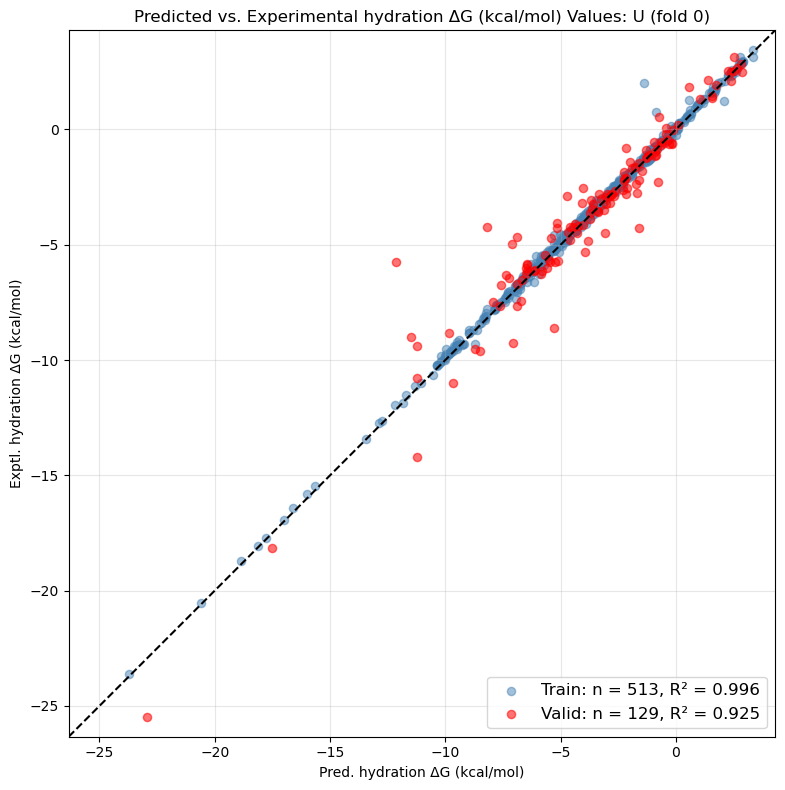

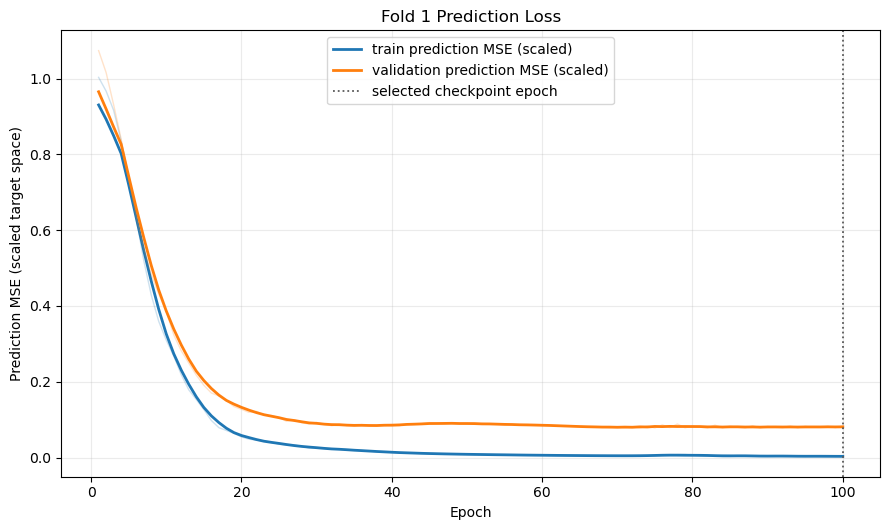

,condition,molecules,all_scaled_pass,all_raw_pass,max_raw_additivity_gap
0,U,642,True,True,0.000002


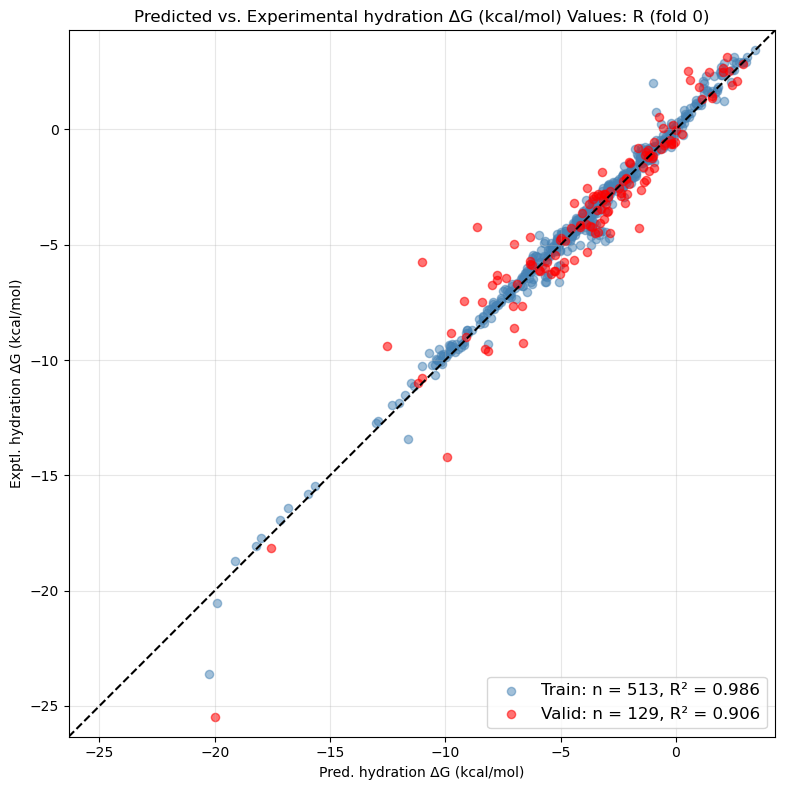

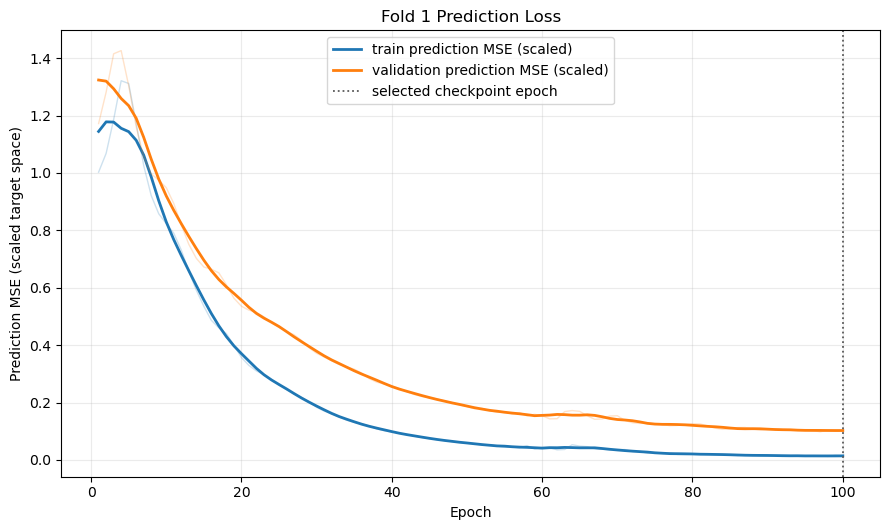

,condition,molecules,all_scaled_pass,all_raw_pass,max_raw_additivity_gap
0,R,642,True,True,0.000002


,split,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw,condition
0,train,513,0.230810,0.134453,0.996319,0.997016,U
1,validation,129,1.096208,0.644769,0.924773,0.925484,U
2,train,513,0.449700,0.303293,0.986027,0.986786,R
3,validation,129,1.222222,0.790695,0.906484,0.906693,R


In [11]:
TARGET_LABEL = "hydration ΔG (kcal/mol)"
TARGET_UNITS = "kcal/mol"
from xai_chem.plotting import (
    plot_train_validation_yy, plot_prediction_loss_curves, save_publication_figure,
)
summary_rows = []
additivity_passed = {}
# U and R use identical axis limits; colours always identify train vs validation.
all_predictions = pd.concat([result.predictions for result in completed.values()])
span = all_predictions[["target_raw", "prediction_raw"]].to_numpy()
padding = 0.03 * max(float(span.max() - span.min()), 1.0)
limits = (float(span.min() - padding), float(span.max() + padding))
for label, result in completed.items():
    figure, scores = plot_train_validation_yy(
        result, run_name=label, limits=limits, target_label=TARGET_LABEL,
    )
    save_publication_figure(figure, run_root / "vis" / f"{label}_yy.png")
    display(figure); plt.close(figure)
    summary_rows.append(scores.assign(condition=label))
    figure = plot_prediction_loss_curves(result)
    save_publication_figure(figure, run_root / "vis" / f"{label}_learning.png")
    display(figure); plt.close(figure)
    audit = check_additivity(result.predictions, result.atom_contributions)
    additivity_passed[label] = bool(audit["scaled_pass"].all() and audit["raw_pass"].all())
    if not additivity_passed[label]:
        raise ValueError(f"Additivity failed for {label}")
    display(pd.DataFrame([{"condition": label, "molecules": len(audit),
        "all_scaled_pass": bool(audit["scaled_pass"].all()), "all_raw_pass": bool(audit["raw_pass"].all()),
        "max_raw_additivity_gap": float(audit["additivity_residual_raw_recomputed"].abs().max())}]))
summary = pd.concat(summary_rows, ignore_index=True)
display(summary)
summary.to_csv(run_root / "prediction_metrics.csv", index=False)


## 10. Reconstruct three structurally selected validation MMPs

Select the three largest changed regions among validation pairs, breaking ties by pair ID. Selection uses structure, not fidelity. RDKit charge, logP, molar refractivity, TPSA, mass, and hydrogen count are interpretable 2D features; these are distinct from the seven descriptors used for SGLT2.

In [12]:
from xai_chem.reconstruction import fit_pair
descriptors = rdkit_atom_descriptors(frame)
teacher = completed["R"].atom_contributions.rename(columns={"source_row_index": "graph_id", "smiles_atom_index": "atom_idx", "atom_contribution_raw": "atom_contribution"})
atom_table = descriptors.merge(teacher[["graph_id", "atom_idx", "atom_contribution"]], on=["graph_id", "atom_idx"], validate="one_to_one")
selected_pairs = mmp[validation_pairs].sort_values(["diff_total_count", "pair_id"], ascending=[False, True]).head(3)
display(selected_pairs[["pair_id", "i_id", "j_id", "diff_total_count"]])
fits = []
fitted_pairs = []
for pair in selected_pairs.itertuples(index=False):
    context = f"FreeSolv_pair_{pair.pair_id}"
    pieces = []
    for graph_id, indices in [(pair.i_id, json.loads(pair.diff_i_json)), (pair.j_id, json.loads(pair.diff_j_json))]:
        pieces.append(atom_table[atom_table["graph_id"].eq(graph_id) & atom_table["atom_idx"].isin(indices)].assign(context_id=context))
    inputs = pd.concat(pieces, ignore_index=True)
    key = pd.Series({"context_id": context, "pair_id": pair.pair_id,
                     "molecule_a": frame.iloc[pair.i_id]["cid"], "molecule_b": frame.iloc[pair.j_id]["cid"]})
    fitted = fit_pair(key, inputs, alpha=1.0, features=RDKit_DESCRIPTORS)
    display(fitted.metrics)
    display(fitted.concept_totals)
    fitted.atoms.to_csv(run_root / f"pair_{pair.pair_id}_atom_reconstruction.csv", index=False)
    fits.append(fitted.metrics.assign(pair_id=pair.pair_id))
    fitted_pairs.append(fitted)
reconstruction = pd.concat(fits, ignore_index=True)
reconstruction.to_csv(run_root / "descriptor_reconstruction.csv", index=False)


,pair_id,i_id,j_id,diff_total_count
1306,1798,35,114,10
195,222,206,367,9
1337,1830,35,608,9


,context_id,pair_id,level,n,r2,rmse,mae,pearson_r,spearman_r,observed_delta,predicted_delta,model_kind,alpha,augmentation_method,n_original_atoms,n_training_rows
0,FreeSolv_pair_1798,1798,A+B diff-region atoms,10,0.949822,0.190494,0.161068,0.977970,1.0,NaN,NaN,ridge,1.0,none,10,10
1,FreeSolv_pair_1798,1798,endpoint A atoms,5,0.986589,0.120353,0.098504,0.998309,1.0,NaN,NaN,ridge,1.0,none,10,10
2,FreeSolv_pair_1798,1798,endpoint B atoms,5,0.779820,0.241021,0.223632,0.949577,1.0,NaN,NaN,ridge,1.0,none,10,10
3,FreeSolv_pair_1798,1798,B-A fragment sum,1,NaN,0.562998,0.562998,NaN,NaN,2.263144,2.826142,ridge,1.0,none,10,10


,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,0.110551,0.000000
1,A,gasteiger_charge,0.037518,-0.075036
2,A,gasteiger_charge_square,0.019445,-0.038889
3,A,crippen_logp,-0.563663,1.127325
4,A,crippen_molar_refractivity,0.080408,-0.160816
5,A,tpsa_A2,0.110459,-0.220919
6,A,atomic_mass,0.209838,-0.419676
7,A,total_hydrogens,-1.307076,2.614152
8,B,shared atom bias,0.110551,0.000000
9,B,gasteiger_charge,-0.037518,-0.075036


,context_id,pair_id,level,n,r2,rmse,mae,pearson_r,spearman_r,observed_delta,predicted_delta,model_kind,alpha,augmentation_method,n_original_atoms,n_training_rows
0,FreeSolv_pair_222,222,A+B diff-region atoms,9,0.884069,0.170502,0.147663,0.981665,0.949153,NaN,NaN,ridge,1.0,none,9,9
1,FreeSolv_pair_222,222,endpoint A atoms,6,0.883051,0.158354,0.141870,0.976842,0.818182,NaN,NaN,ridge,1.0,none,9,9
2,FreeSolv_pair_222,222,endpoint B atoms,3,0.885340,0.192512,0.159247,0.989949,1.000000,NaN,NaN,ridge,1.0,none,9,9
3,FreeSolv_pair_222,222,B-A fragment sum,1,NaN,0.117655,0.117655,NaN,NaN,0.063451,0.181106,ridge,1.0,none,9,9


,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,-0.273791,0.136895
1,A,gasteiger_charge,-0.186354,0.372708
2,A,gasteiger_charge_square,0.230368,-0.460737
3,A,crippen_logp,0.695273,-1.390546
4,A,crippen_molar_refractivity,0.042648,-0.085296
5,A,tpsa_A2,0.060739,-0.121478
6,A,atomic_mass,0.060739,-0.121478
7,A,total_hydrogens,-0.925518,1.851036
8,B,shared atom bias,-0.136895,0.136895
9,B,gasteiger_charge,0.186354,0.372708


,context_id,pair_id,level,n,r2,rmse,mae,pearson_r,spearman_r,observed_delta,predicted_delta,model_kind,alpha,augmentation_method,n_original_atoms,n_training_rows
0,FreeSolv_pair_1830,1830,A+B diff-region atoms,9,0.943797,0.242339,0.185558,0.974639,0.966667,NaN,NaN,ridge,1.0,none,9,9
1,FreeSolv_pair_1830,1830,endpoint A atoms,5,0.974899,0.164655,0.140720,0.999494,1.000000,NaN,NaN,ridge,1.0,none,9,9
2,FreeSolv_pair_1830,1830,endpoint B atoms,4,0.901821,0.313448,0.241606,0.955646,1.000000,NaN,NaN,ridge,1.0,none,9,9
3,FreeSolv_pair_1830,1830,B-A fragment sum,1,NaN,0.825970,0.825970,NaN,NaN,0.119593,0.945563,ridge,1.0,none,9,9


,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,-1.068027,0.213605
1,A,gasteiger_charge,0.076146,-0.152291
2,A,gasteiger_charge_square,-0.105254,0.210508
3,A,crippen_logp,-0.120244,0.240487
4,A,crippen_molar_refractivity,0.073500,-0.147000
5,A,tpsa_A2,-0.008504,0.017008
6,A,atomic_mass,0.025221,-0.050443
7,A,total_hydrogens,-0.306844,0.613689
8,B,shared atom bias,-0.854422,0.213605
9,B,gasteiger_charge,-0.076146,-0.152291


## 11. Inspect raw ACs and fitted atom values

One global symmetric color scale covers all selected endpoint molecules. Raw
values are unchanged, the affine baseline is separate, and every atom index and
numerical contribution is visible. The table records prediction, observation,
error, and baseline in kcal/mol.

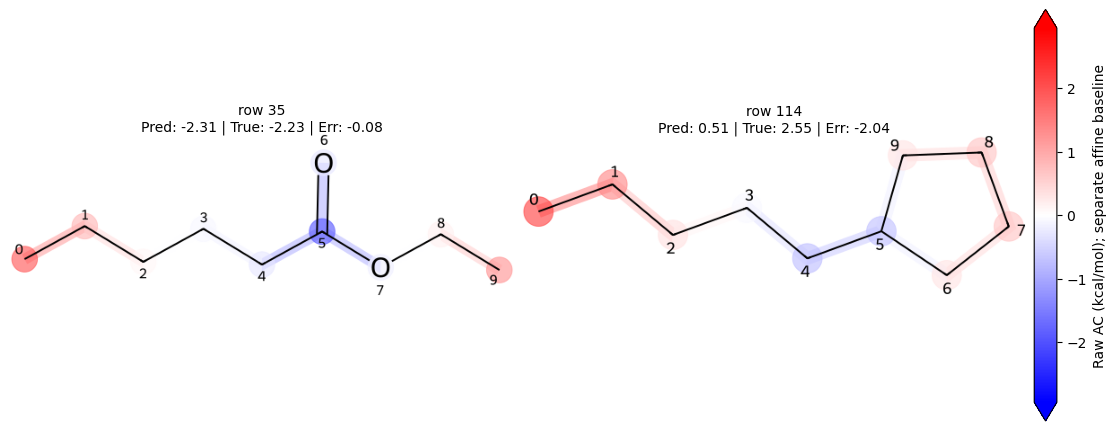

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,35,,validation,CCCCCC(=O)OCC,-2.23,-2.312471,-0.082471,-3.848616,1.536145,2.384186e-07,0,0.0
1,114,,validation,CCCCCC1CCCC1,2.55,0.514747,-2.035253,-3.848616,4.363363,4.768372e-07,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,35,0,C,1.973111,1.973111
1,molecule,35,1,C,0.875209,0.875209
2,molecule,35,2,C,0.097395,0.097395
3,molecule,35,3,C,-0.099289,0.099289
4,molecule,35,4,C,-0.289260,0.289260
5,molecule,35,5,C,-1.970674,1.970674
6,molecule,35,6,O,-0.277254,0.277254
7,molecule,35,7,O,-0.205403,0.205403
8,molecule,35,8,C,0.177371,0.177371
9,molecule,35,9,C,1.254939,1.254939


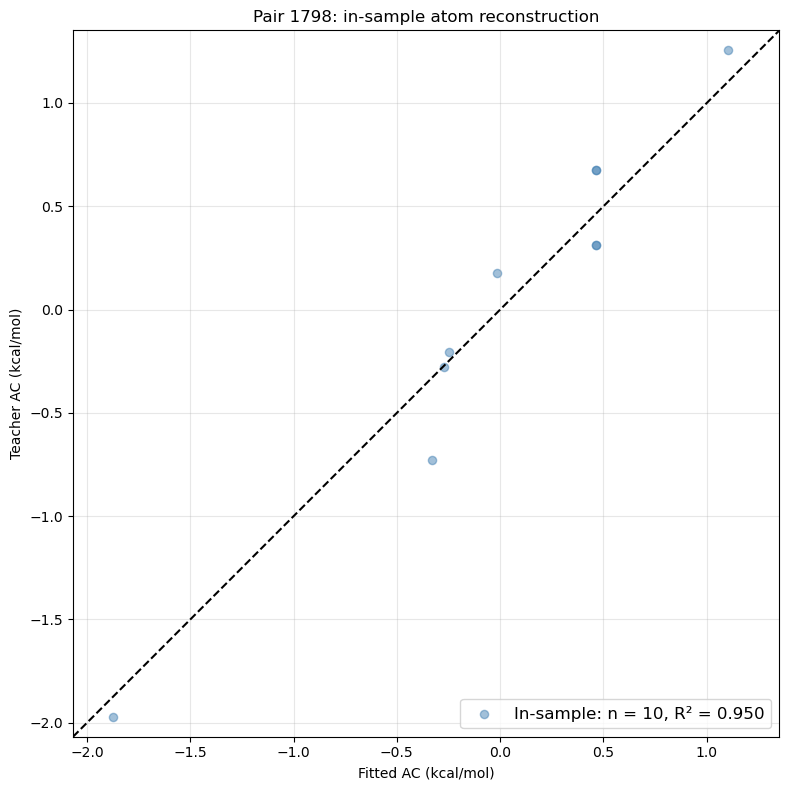

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,10,0.190494,0.161068,0.949822,0.956426


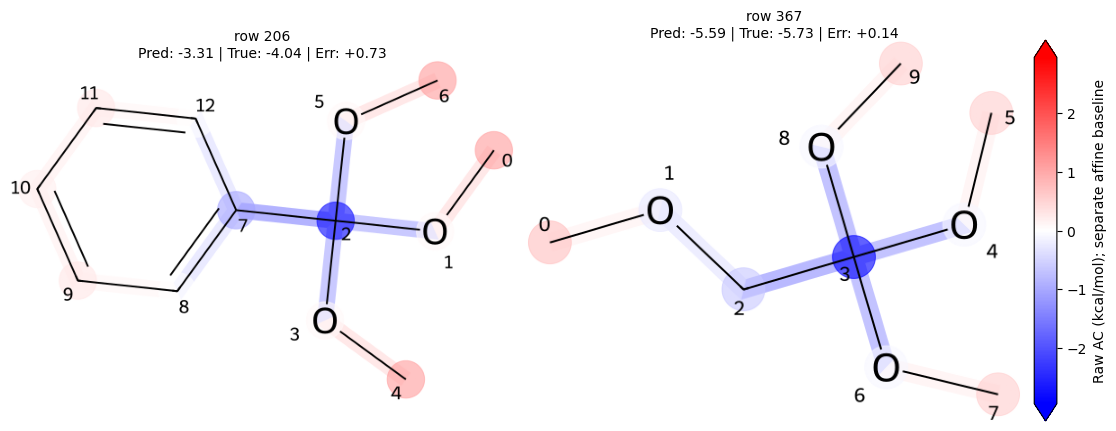

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,206,,validation,COC(OC)(OC)c1ccccc1,-4.04,-3.306985,0.733015,-3.848616,0.541630,2.384186e-07,0,0.0
1,367,,validation,COCC(OC)(OC)OC,-5.73,-5.587800,0.142200,-3.848616,-1.739183,-4.768372e-07,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,206,0,C,1.121570,1.121570
1,molecule,206,1,O,0.069237,0.069237
2,molecule,206,2,C,-2.793722,2.793722
3,molecule,206,3,O,0.069237,0.069237
4,molecule,206,4,C,1.121570,1.121570
5,molecule,206,5,O,0.069237,0.069237
6,molecule,206,6,C,1.121570,1.121570
7,molecule,206,7,C,-1.041154,1.041154
8,molecule,206,8,C,0.008990,0.008990
9,molecule,206,9,C,0.292920,0.292920


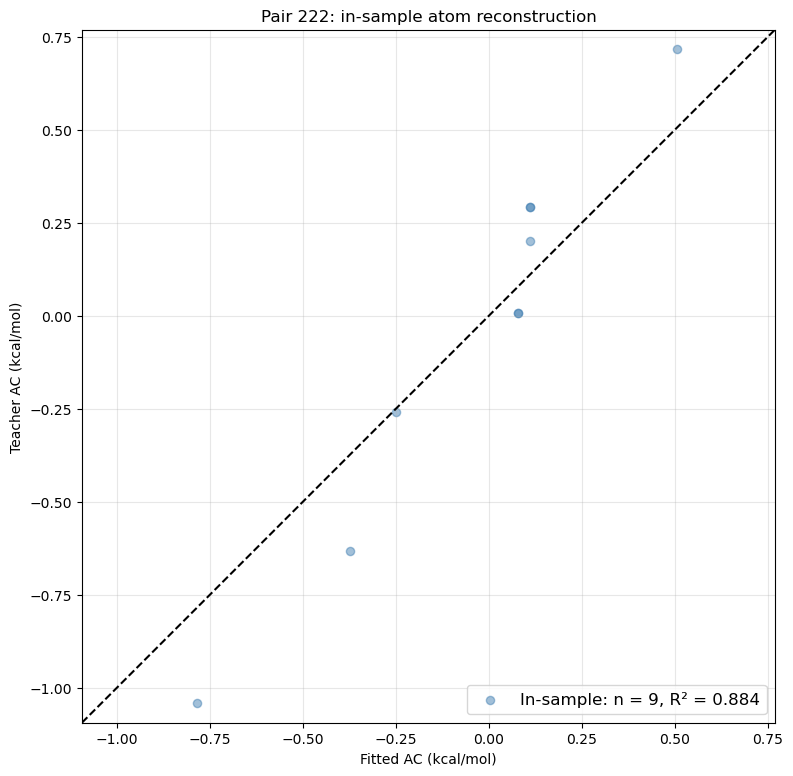

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,9,0.170502,0.147663,0.884069,0.963667


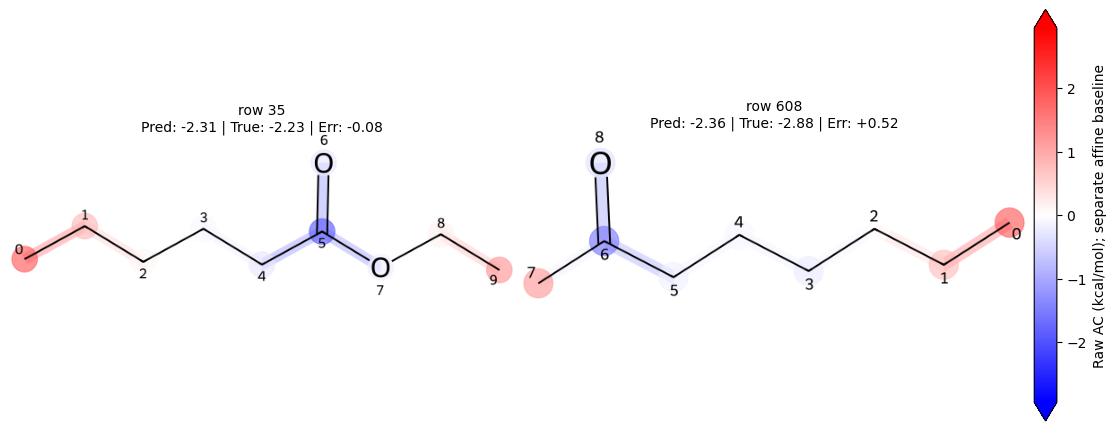

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,35,,validation,CCCCCC(=O)OCC,-2.23,-2.312471,-0.082471,-3.848616,1.536145,2.384186e-07,0,0.0
1,608,,validation,CCCCCCC(C)=O,-2.88,-2.363636,0.516364,-3.848616,1.484979,0.000000e+00,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,35,0,C,1.973111,1.973111
1,molecule,35,1,C,0.875209,0.875209
2,molecule,35,2,C,0.097395,0.097395
3,molecule,35,3,C,-0.099289,0.099289
4,molecule,35,4,C,-0.289260,0.289260
5,molecule,35,5,C,-1.970674,1.970674
6,molecule,35,6,O,-0.277254,0.277254
7,molecule,35,7,O,-0.205403,0.205403
8,molecule,35,8,C,0.177371,0.177371
9,molecule,35,9,C,1.254939,1.254939


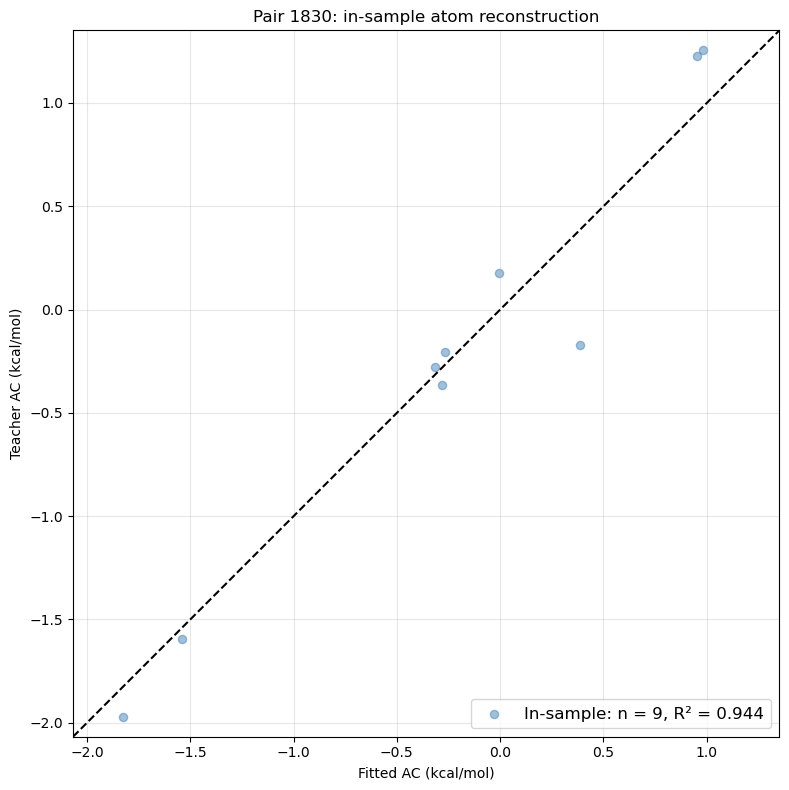

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,9,0.242339,0.185558,0.943797,0.949921


In [13]:
from xai_chem.plotting import plot_atom_contribution_grid, plot_reconstruction_yy

selected_graph_ids = set(selected_pairs["i_id"]) | set(selected_pairs["j_id"])
selected_atoms = atom_table[atom_table["graph_id"].isin(selected_graph_ids)]
shared_limit = float(selected_atoms["atom_contribution"].abs().max())
for pair, fitted in zip(selected_pairs.itertuples(index=False), fitted_pairs):
    # The standard project grid includes molecule, prediction, truth, and error.
    figure, molecule_audit, atom_audit = plot_atom_contribution_grid(
        completed["R"], source_rows=[pair.i_id, pair.j_id], symmetric_limit=shared_limit,
        draw_atom_indices=True, contribution_label=f"Raw AC ({TARGET_UNITS}); separate affine baseline",
    )
    save_publication_figure(figure, run_root / "vis" / f"pair_{pair.pair_id}_raw_ac.png")
    molecule_audit.to_csv(run_root / f"pair_{pair.pair_id}_map_audit.csv", index=False)
    atom_audit.to_csv(run_root / f"pair_{pair.pair_id}_raw_atom_values.csv", index=False)
    display(figure); plt.close(figure)
    display(molecule_audit)
    display(atom_audit)
    figure, scores = plot_reconstruction_yy(
        fitted.atoms["atom_contribution"], fitted.atoms["prediction"],
        unit_label=f"AC ({TARGET_UNITS})", title=f"Pair {pair.pair_id}: in-sample atom reconstruction",
    )
    save_publication_figure(figure, run_root / "vis" / f"pair_{pair.pair_id}_reconstruction_yy.png")
    display(figure); plt.close(figure)
    display(scores)


Raw ACs decompose the model prediction. The pairwise fit uses only changed-region atoms and is in-sample; it does not validate a causal or transferable physicochemical attribution.

## 12. Acceptance record

In [14]:
training_decreased = {
    label: bool(result.history.iloc[-1]["optimization_prediction_mse_scaled"] < result.history.iloc[0]["optimization_prediction_mse_scaled"])
    for label, result in completed.items()
}
record = {"dataset": "FreeSolv_v0.52", "molecules": len(frame), "target": "hydration_kcal_mol",
          "target_units": "kcal/mol", "fold": 0, "seed": SEED, "epochs": EPOCHS,
          "training_prediction_loss_decreased": training_decreased,
          "all_models_additive": all(additivity_passed.values()),
          "all_four_training_constraints_lower": bool((ratios < 1).all()),
          "training_constraint_ratios_R_div_U": {key: float(value) for key, value in ratios.items()},
          "descriptor_pairs": len(selected_pairs), "ridge_alpha": 1.0,
          "descriptor_contract": list(RDKit_DESCRIPTORS), "reconstruction_scope": "in_sample_diff_region_atoms"}
print(json.dumps(record, indent=2))
(run_root / "acceptance.json").write_text(json.dumps(record, indent=2, allow_nan=False) + "\n")
if not all(training_decreased.values()) or not record["all_four_training_constraints_lower"] or len(selected_pairs) != 3:
    raise ValueError("FreeSolv acceptance condition was not met; inspect the measured results")

{
  "dataset": "FreeSolv_v0.52",
  "molecules": 642,
  "target": "hydration_kcal_mol",
  "target_units": "kcal/mol",
  "fold": 0,
  "seed": 42,
  "epochs": 100,
  "training_prediction_loss_decreased": {
    "U": true,
    "R": true
  },
  "all_models_additive": true,
  "all_four_training_constraints_lower": true,
  "training_constraint_ratios_R_div_U": {
    "core": 0.4338350512057874,
    "difference": 0.7174405998812613,
    "positive": 0.0,
    "consistency": 0.001878056921543847
  },
  "descriptor_pairs": 3,
  "ridge_alpha": 1.0,
  "descriptor_contract": [
    "gasteiger_charge",
    "gasteiger_charge_square",
    "crippen_logp",
    "crippen_molar_refractivity",
    "tpsa_A2",
    "atomic_mass",
    "total_hydrogens"
  ],
  "reconstruction_scope": "in_sample_diff_region_atoms"
}


The experiment establishes the measured training and constraint behavior only for the declared split and settings. A lower regularization penalty is not evidence of physically correct ACs. Ridge fidelity is in-sample reconstruction, not predictive accuracy on unseen atoms. Negative hydration energies are preserved, and recurrent-fragment positivity remains a model-design assumption that should be reconsidered for each endpoint.